In [126]:
import geopandas as gpd
import pandas as pd
import rasterio

print("Welcome to Python for GIS!")
print("GeoPandas version:", gpd.__version__)
print("Pandas version:", pd.__version__)
print("Rasterio version:", rasterio.__version__)

Welcome to Python for GIS!
GeoPandas version: 1.2.0
Pandas version: 3.1.1
Rasterio version: 1.4.4


In [127]:
# Store information about a study area

study_area = "Aberdare Forest"
county = "Nyeri"
area_hectares = 226522
ndvi_value = 0.65
is_forest = True

print(study_area)
print(county)
print(area_hectares)
print(ndvi_value)
print(is_forest)

Aberdare Forest
Nyeri
226522
0.65
True


In [128]:
from shapely.geometry import Point
point1 = Point(36.9500, -0.4167)  # Longitude, Latitude
point2 = Point(36.9600, -0.4200)
point3 = Point(36.9700, -0.4300)
point4_3d = Point(36.9800, -0.4400, 1500)  # 3D point with elevation

In [129]:
print(point1)
print(point2)
print(point3)   
print(point4_3d)  # This will print the 3D point with elevation

POINT (36.95 -0.4167)
POINT (36.96 -0.42)
POINT (36.97 -0.43)
POINT Z (36.98 -0.44 1500)


In [130]:
type(point1)  # This will return <class 'shapely.geometry.point.Point'>


shapely.geometry.point.Point

In [131]:
list(point1.coords)  # This will return the coordinates of point1 as a list of tuples
list(point2.coords)  # This will return the coordinates of point2 as a list of tuples
list(point3.coords)  # This will return the coordinates of point3 as a list of tuples
list(point4_3d.coords)  # This will return the coordinates of point4_3d as a list of tuples


[(36.98, -0.44, 1500.0)]

In [132]:
x = point1.x  # This will return the x-coordinate (longitude) of point1
y = point1.y  # This will return the y-coordinate (latitude) of point1

In [133]:
x = point4_3d.x  # This will return the x-coordinate (longitude) of point4_3d
y = point4_3d.y  # This will return the y-coordinate (latitude) of point4_3d
z = point4_3d.z  # This will return the z-coordinate (elevation ) of point4_3d              


In [134]:
dist = point1.distance(point2)  # This will calculate the distance between point1 and point2
print(dist)  # This will print the calculated distance
print(f"Distance between point1 and point2 is {dist:.2f} meters")  # This will print the distance with 2 decimal places

0.010530432089898307
Distance between point1 and point2 is 0.01 meters


In [135]:
from shapely.geometry import LineString
line = LineString([point1, point2, point3])  # Create a LineString from the three points

In [136]:
line2 = LineString([(36.95, -0.4167), (36.96, -0.42), (36.9800, -0.4400), (36.99, -0.45)])  # Create a LineString from the three points and the 3D point

In [137]:
line == line2

False

In [138]:
type(line)  # This will return <class 'shapely.geometry.linestring.LineString'>


shapely.geometry.linestring.LineString

In [139]:
line.geom_type

'LineString'

In [140]:
for x in line.coords:
    print(x)  # This will print each coordinate of the line as a tuple
    

(36.95, -0.4167)
(36.96, -0.42)
(36.97, -0.43)


In [141]:
list(line.coords)  # This will return the coordinates of the line as a list of tuples


[(36.95, -0.4167), (36.96, -0.42), (36.97, -0.43)]

In [142]:
xcoords =list(line.xy[0])  # This will return the x-coordinates of the line as a list
ycoords =list(line.xy[1])  # This will return the y-coordinates of the line as a list   
print(xcoords)  # This will print the x-coordinates of the line
print(ycoords)  # This will print the y-coordinates of the line 



[36.95, 36.96, 36.97]
[-0.4167, -0.42, -0.43]


In [143]:
line_length = line.length  # This will calculate the length of the   LineString
print(f"length of ourline:{line_length:.1f} meters")  # This will print the length of the line with 1 decimal place

length of ourline:0.0 meters


In [144]:
print(line.centroid)  # This will print the centroid of the line as a Point object


POINT (36.96073192696759 -0.4221617314334436)


In [145]:

from shapely.geometry import Polygon
polygon1 = Polygon([
    (36.95, -0.4167),
    (36.96, -0.42),
    (36.9800, -0.4400),
    (36.99, -0.45)
])


In [146]:
from shapely.geometry import LinearRing
shell = LinearRing([point1, point2, point3, point1])  # Create a LinearRing from the three points
polygon3 = Polygon(shell)  # Create a Polygon from the LinearRing


In [120]:
polygon1 == polygon3  # This will return True if the two polygons are equal, False otherwise


False

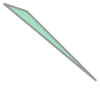

In [147]:
polygon1


In [148]:
type(polygon1)  # This will return <class 'shapely.geometry.polygon.Polygon'>


shapely.geometry.polygon.Polygon

In [149]:
polygon1.geom_type

'Polygon'

In [150]:
help(polygon)

NameError: name 'polygon' is not defined

In [ ]:
outer = LinearRing([(-36.56, -90), (-36.56, -89), (-35.56, 89), (-35.56, 90), (36.56, 90)])
hole = LinearRing([(-36.56, -89), (-36.56, -88), (-35.56, 88), (-35.56, 89), (36.56, 89)])

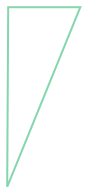

In [ ]:
outer

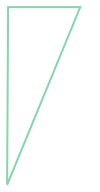

In [ ]:
hole

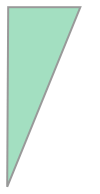

In [ ]:
polygon_without_hole = Polygon(outer)  # Create a Polygon without a hole
polygon_without_hole

In [125]:
polygon_with_hole = Polygon(outer, [hole])  # Create a Polygon with a hole
polygon_with_hole

NameError: name 'outer' is not defined

In [ ]:
print(polygon_without_hole) 
print(polygon_with_hole)
 # This will print the area of the polygon without a hole

POLYGON ((-36.56 -90, -36.56 -89, -35.56 89, -35.56 90, 36.56 90, -36.56 -90))
POLYGON ((-36.56 -90, -36.56 -89, -35.56 89, -35.56 90, 36.56 90, -36.56 -90), (-36.56 -89, -36.56 -88, -35.56 88, -35.56 89, 36.56 89, -36.56 -89))


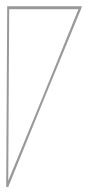

In [ ]:
polygon_with_hole

In [ ]:
print(f"polygon centroid: {polygon_with_hole.centroid}")  # This will print the centroid of the polygon with a hole
print(f"polygon area: {polygon_with_hole.area}")  # This will print the area of the polygon with a hole
print(f"polygon bounding box: [{polygon_with_hole.bounds}]")  # This will print the bounding box of the polygon with a hole
print(f"polygon exterior ring: {(polygon_with_hole.exterior)}")  # This will print the exterior coordinates of the polygon with a hole
print(f" polygon circumference: {polygon_with_hole.exterior.length}")  # This will print the circumference of the polygon with a hole


polygon centroid: POINT (-11.853333333333321 59.66204474024764)
polygon area: 72.11999999999989
polygon bounding box: [(-36.56, -90.0, 36.56, 90.0)]
polygon exterior ring: LINEARRING (-36.56 -90, -36.56 -89, -35.56 89, -35.56 90, 36.56 90, -36.56 -90)
 polygon circumference: 446.4074825772585


In [ ]:
polygon_with_hole.interiors

In [ ]:
for x in polygon_with_hole.interiors:
    print(x)  # This will print each interior ring of the polygon with a hole
    

LINEARRING (-36.56 -89, -36.56 -88, -35.56 88, -35.56 89, 36.56 89, -36.56 -89)


In [ ]:
# pentagon
pentagon = Polygon([
    (36.2, 0),
    (36.9, 2),
    (37.8, 2.5),
    (38.2, 1),
    (37.2, -1),
    (36.2, 0)
])
print(pentagon)

POLYGON ((36.2 0, 36.9 2, 37.8 2.5, 38.2 1, 37.2 -1, 36.2 0))


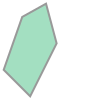

In [ ]:
pentagon

In [ ]:
square = Polygon([
    (36.2, 0),  
    (36.2, 2),
    (38.2, 2),
    (38.2, 0),
    (36.2, 0)
])
print(square)

POLYGON ((36.2 0, 36.2 2, 38.2 2, 38.2 0, 36.2 0))


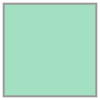

In [ ]:
square

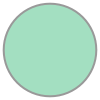

In [ ]:
point = Point(36.5, 1)  # Create a Point object at (36.5, 1)
point.buffer(4)

In [ ]:
# Create a MultiPoint from the three points
from shapely import MultiLineString, MultiPoint


multipoint = MultiPoint([point1, point2, point3])

# Create two LineStrings
line1 = LineString([point1, point2])
line2 = LineString([point2, point3])

# Create a MultiLineString
multiline = MultiLineString([line1, line2])

# Print the results
print(multipoint)
print(multiline)

MULTIPOINT ((36.95 -0.4167), (36.96 -0.42), (36.97 -0.43))
MULTILINESTRING ((36.95 -0.4167, 36.96 -0.42), (36.96 -0.42, 36.97 -0.43))


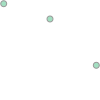

In [ ]:
multipoint

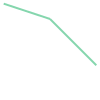

In [ ]:
multiline

In [ ]:
western_kenya = Polygon([
    (34.0, 0.0),
    (34.0, 5.0),
    (37.0, 5.0),
    (37.0, 0.0),
    (34.0, 0.0)
])
print(western_kenya)


POLYGON ((34 0, 34 5, 37 5, 37 0, 34 0))


In [ ]:
from shapely.geometry import Point, MultiPoint

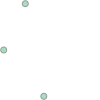

In [ ]:

from shapely.geometry import Point, MultiPoint

# Create three points
point1 = Point(36.2, 0.5)
point2 = Point(36.9, 2.0)
point3 = Point(37.5, -1.0)

# Create a MultiPoint
multipoint = MultiPoint([point1, point2, point3])

# Display the MultiPoint
multipoint

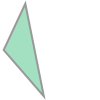

In [ ]:
# Convex Hull
multipoint.convex_hull

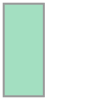

In [ ]:
multipoint.envelope

In [ ]:
polygon_with_hole.is_valid

NameError: name 'polygon_with_hole' is not defined